# Spherical, oblate and ringed planets with Elómë

Elómë computes transit light curves -- `(parameters, times) -> flux` --
and that map's derivatives, on the CPU in float64 or on an Apple GPU in
float32. The planet may be **spherical** (a disc on the sky) or
**oblate** (an ellipse on the sky: a rotationally flattened planet, or one
seen with its pole tilted), and either may carry a flat **ring**.

The cases share one API, but they are worth learning separately,
because they differ in what they can do and in what they cost:

| | spherical planet | oblate planet | ringed planet |
|---|---|---|---|
| shape on the sky | disc, radius `rp` | ellipse: area-equivalent radius `rp`, flattening `f`, angle `theta` | the planet, plus an elliptical annulus: `ring_in`, `ring_out`, `ring_f`, `ring_tau`, angle `theta` |
| limb darkening | uniform, linear, quadratic, polynomial, hybrid2/4/5 | hybrid2/4/5 | hybrid2/4/5 |
| cost (fp32 GPU) | ~0.2 ns per point | tens of times more (B8) | 10-20x an oblate planet (C4) |
| switch | leave `f` as `None` (the default) | set `f` | set `ring_in` |

**Part A** walks through a spherical planet; **Part B** repeats the same
steps for an oblate one and adds what is new; **Part C** adds a ring.
Everything runs in about a minute. Figures need `matplotlib`; without it every cell still prints its
numbers.

## 0. Setup

In [1]:
import copy
import math
import time

import numpy as np
import mlx.core as mx

import elome as el

try:
    import matplotlib.pyplot as plt
    HAVE_PLT = True
except ImportError:
    HAVE_PLT = False

print("elome", el.__version__, "| Metal kernels available:", el.metal_available())

def timeit(fn, reps=5):
    """Best of `reps` wall-clock times of fn() in ms (fn must finish its work)."""
    fn()
    best = float("inf")
    for _ in range(reps):
        t0 = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t0)
    return best * 1e3

elome 0.18.4 | Metal kernels available: True


# Part A -- a spherical planet

## A1. A first light curve

The frontend mirrors `batman`: fill in a `TransitParams`, hand it and a time
grid to `TransitModel`, call `light_curve`. Angles (`inc`, `w`) are in
degrees; `rp` and `a` are in stellar radii.

impact parameter b = 0.461, depth = 11518 ppm


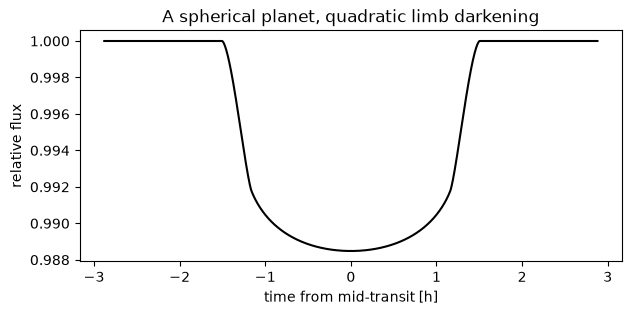

In [2]:
p = el.TransitParams()
p.t0 = 0.0            # time of inferior conjunction [d]
p.per = 3.456         # orbital period [d]
p.rp = 0.1            # Rp / R*
p.a = 8.8             # a / R*
p.inc = 87.0          # inclination [deg]
p.ecc = 0.0
p.w = 90.0            # argument of periastron [deg]
p.limb_dark = "quadratic"
p.u = [0.40, 0.25]

t = np.linspace(-0.12, 0.12, 2001)   # days around mid-transit
m = el.TransitModel(p, t)            # float64 on the CPU by default
flux = m.light_curve(p)

b = p.a * math.cos(math.radians(p.inc))
print(f"impact parameter b = {b:.3f}, depth = {(1 - flux.min()) * 1e6:.0f} ppm")

if HAVE_PLT:
    plt.figure(figsize=(7, 3))
    plt.plot(t * 24, flux, "k")
    plt.xlabel("time from mid-transit [h]"); plt.ylabel("relative flux")
    plt.title("A spherical planet, quadratic limb darkening"); plt.show()

`TransitModel` precomputes everything that depends on the time grid, so you
build it once and change parameters freely between calls -- the `batman`
workflow. What is fixed per model is the limb-darkening *law* (and, as we
will see, whether the planet is oblate).

## A2. Hybrid limb darkening

The quadratic law is the default, but Elómë also has three **hybrid
laws**: even powers of $\mu$ plus "double-pole"
terms $(\mu^2+\epsilon)^{-2}$ that follow a real star's steep fall at the
limb. Across PHOENIX and MPS-ATLAS stellar models in 37 passbands the
median light-curve error is 1.8 ppm for `hybrid4` and 1.1 ppm for
`hybrid5`, against 2.0 ppm for Claret's four-parameter law.

Their coefficients `u` are **shape weights**: each is the share of the
centre-to-limb drop its shape carries, so $I(0)/I(1) = 1 - \sum w$.
`simplex_from_q_np` maps the unit cube uniformly onto `hybrid5`'s simplex
of physical weights, which is what you want for a prior; `hybrid4` has
its own map, `hybrid4_from_q_np`, onto its curvature simplex.

The hybrid laws matter for Part B: **they are the only laws an oblate
planet can use.**

hybrid5 weights: [0.214  0.1251 0.2744 0.0871 0.1796] | centre-to-limb drop: 0.8802


hybrid5 depth = 11714 ppm


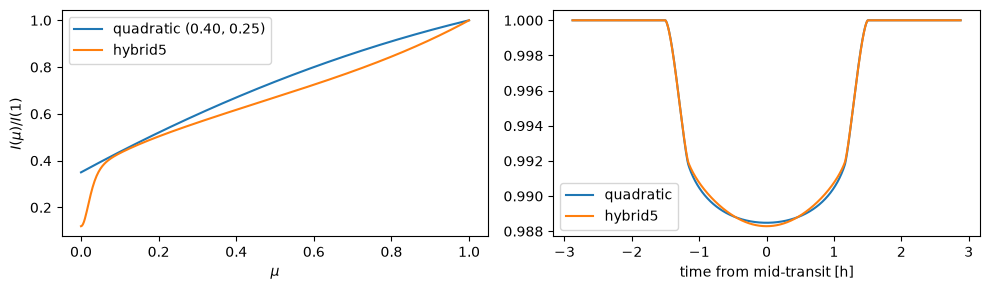

In [3]:
w5 = el.simplex_from_q_np([0.3, 0.5, 0.2, 0.6, 0.4])   # 5 weights in the physical simplex
print("hybrid5 weights:", np.round(w5, 4), "| centre-to-limb drop:", round(float(w5.sum()), 4))

ph = copy.copy(p)
ph.limb_dark, ph.u = "hybrid5", list(w5)
flux_h5 = el.TransitModel(ph, t).light_curve(ph)
print(f"hybrid5 depth = {(1 - flux_h5.min()) * 1e6:.0f} ppm")

# the intensity profiles behind the two curves: I/I(1) = 1 - sum_j w_j T_j(mu),
# hybrid5's shape terms T = [1 - mu^4, (1 - mu^2)^2, Pi_eps for each pole]
mu = np.linspace(0, 1, 401)
def pole_shape(mu, eps):
    p_ = 1 + eps
    return ((mu**2 + eps)**-2 - p_**-2) / (eps**-2 - p_**-2)
T = [1 - mu**4, (1 - mu**2)**2] + [pole_shape(mu, e) for e in el.HYBRID5.eps]
I_h5 = 1 - sum(wj * Tj for wj, Tj in zip(w5, T))
I_q = 1 - 0.40 * (1 - mu) - 0.25 * (1 - mu)**2

if HAVE_PLT:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(mu, I_q, label="quadratic (0.40, 0.25)")
    ax[0].plot(mu, I_h5, label="hybrid5")
    ax[0].set_xlabel(r"$\mu$"); ax[0].set_ylabel(r"$I(\mu)/I(1)$"); ax[0].legend()
    ax[1].plot(t * 24, flux, label="quadratic"); ax[1].plot(t * 24, flux_h5, label="hybrid5")
    ax[1].set_xlabel("time from mid-transit [h]"); ax[1].legend(); plt.tight_layout(); plt.show()

## A3. Finite exposures

A long-cadence point is an *average* over its exposure. `TransitModel`
offers batman's supersampling, and a **contact rule**: Gauss-Legendre
quadrature on each exposure, split at the four contact points where the
light curve has kinks. The contact rule needs far fewer evaluations for
the same accuracy.

In [4]:
EXP = 29.4 / 60 / 24                      # Kepler long cadence [d]
tc = np.linspace(-0.12, 0.12, 241)
ref = el.TransitModel(p, tc, supersample_factor=401, exp_time=EXP).light_curve(p)
for label, kw in [("instantaneous", {}),
                  ("supersample x 7", dict(supersample_factor=7, exp_time=EXP)),
                  ("contact rule, n_gl = 5", dict(integration="contact", exp_time=EXP, n_gl=5))]:
    f_ = el.TransitModel(p, tc, **kw).light_curve(p)
    print(f"{label:24s} max |error| vs 401-point supersampling: {np.abs(f_ - ref).max():.1e}")

instantaneous            max |error| vs 401-point supersampling: 1.3e-03
supersample x 7          max |error| vs 401-point supersampling: 2.8e-04


contact rule, n_gl = 5   max |error| vs 401-point supersampling: 4.5e-06


## A4. Gradients

`light_curve_mx` returns the light curve as an MLX array that stays in the
graph. Make any parameter an `mx.array` and `mx.grad` differentiates through
it. The default model is float64 on the CPU, so take the gradient on the CPU
stream.

In [5]:
with mx.stream(mx.cpu):
    def loss(rp, inc):
        q = copy.copy(p)
        q.rp, q.inc = rp, inc
        return mx.sum(m.light_curve_mx(q))
    g_rp, g_inc = mx.grad(loss, argnums=(0, 1))(mx.array(0.1, dtype=mx.float64),
                                                mx.array(87.0, dtype=mx.float64))
    h = 1e-6
    fd = (float(loss(mx.array(0.1 + h, dtype=mx.float64), mx.array(87.0, dtype=mx.float64)))
          - float(loss(mx.array(0.1 - h, dtype=mx.float64), mx.array(87.0, dtype=mx.float64)))) / (2 * h)
print(f"d(sum flux)/d rp : autodiff {float(g_rp):+.6f}  finite difference {fd:+.6f}")
print(f"d(sum flux)/d inc: autodiff {float(g_inc):+.6f} per degree")

d(sum flux)/d rp : autodiff -189.210176  finite difference -189.210176
d(sum flux)/d inc: autodiff -1.218494 per degree


## A5. Many parameter sets, and the GPU

A sampler evaluates thousands of parameter sets per step. `light_curves`
takes them all in one call -- here as a `TransitParams` whose fields are
arrays. With `dtype=mx.float32` the model runs on the GPU in fused Metal
kernels: the precision is ~1e-7.

`light_curves` hands back a numpy array, and for 10 million points that
copy dominates the call. A sampler keeps everything on the GPU instead;
`flux_dev_from_tau` (A6) times the kernel itself.

In [6]:
rng = np.random.default_rng(0)
n_sets = 512
pa = copy.copy(p)
pa.rp = 0.1 * (1 + 0.05 * rng.standard_normal(n_sets))
pa.inc = 87.0 + 0.5 * rng.standard_normal(n_sets)

t_big = np.linspace(-0.12, 0.12, 20_000)
m64 = el.TransitModel(p, t_big)
m32 = el.TransitModel(p, t_big, dtype=mx.float32)
print("fp32 vs fp64, one set:", f"{np.abs(m32.light_curve(p) - m64.light_curve(p)).max():.1e}")
npts = n_sets * t_big.size
ms = timeit(lambda: m32.light_curves(pa))
print(f"light_curves, {n_sets} sets x {t_big.size:,} points (returned as numpy): {ms:.1f} ms")

# the same evaluation kept on the GPU, as a sampler runs it
tau_b = mx.array(np.tile(t_big, (n_sets, 1)), dtype=mx.float32)      # t0 = 0: tau = t
rp_b = mx.array(pa.rp, dtype=mx.float32)
b_b = mx.array(8.8 * np.cos(np.radians(pa.inc)), dtype=mx.float32)
ms_k = timeit(lambda: mx.eval(el.flux_dev_from_tau(tau_b, 3.456, 8.8, b_b, rp_b, 0.40, 0.25)))
print(f"flux_dev_from_tau on the GPU, same points: {ms_k:.2f} ms ({ms_k * 1e6 / npts:.2f} ns per point)")

fp32 vs fp64, one set: 2.0e-07


light_curves, 512 sets x 20,000 points (returned as numpy): 55.2 ms
flux_dev_from_tau on the GPU, same points: 2.49 ms (0.24 ns per point)


## A6. The sampler-facing entry point

For samplers there is a lower-level function, `flux_dev_from_tau`: it takes
each point's time since **its own** mid-transit (so per-transit timing
variations are just a different `tau`), per-chain parameters, and an
exposure rule. It returns `F - 1`. With `ld_basis=True` it returns the
limb-darkening *columns* instead, so a sampler can treat the weights as a
linear block and integrate them out analytically.

In [7]:
tau = np.linspace(-0.12, 0.12, 1000)
dev = el.flux_dev_from_tau(tau, 3.456, 8.8, b, 0.1, limb_dark="hybrid5", u=list(w5))
B = el.flux_dev_from_tau(tau, 3.456, 8.8, b, 0.1, limb_dark="hybrid5", ld_basis=True)
c_ = np.concatenate([[1.0], -w5])
print("columns:", np.asarray(B).shape, "| identity (B @ c)/(N @ c) == F - 1:",
      f"{np.abs(np.asarray(B) @ c_ / (el.hybrid_norms('hybrid5') @ c_) - np.asarray(dev)).max():.1e}")

columns: (1000, 6) | identity (B @ c)/(N @ c) == F - 1: 3.5e-18


# Part B -- an oblate planet

## B1. The geometry

A flattened planet projects to an **ellipse** on the sky. Elómë
describes it with three numbers:

* `rp` -- the **area-equivalent radius** $\sqrt{AB}$, so the planet blocks
  the same area as a sphere of radius `rp` (the transit depth stays put
  when you vary the shape);
* `f` -- the projected **flattening** $1 - B/A$ (Jupiter ~0.065, Saturn
  ~0.098);
* `theta` -- the sky angle of the long axis, measured from the direction of
  motion at mid-transit, **in degrees** on `TransitParams` (radians in
  `flux_dev_from_tau`). It has period 180 deg: the ellipse is symmetric.

The semi-axes are $A = r_p/\sqrt{1-f}$ and $B = A(1-f)$. The conventions
match squishyplanet's projected-ellipse parameters.

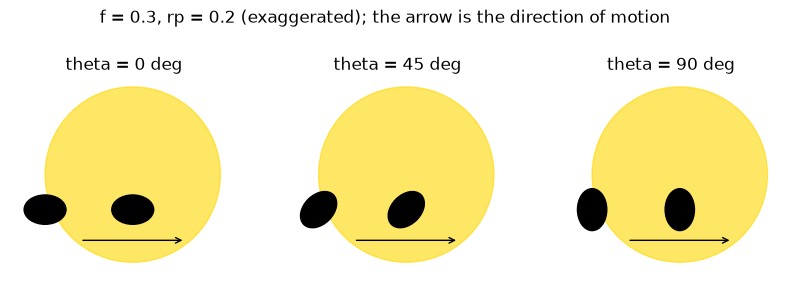

In [8]:
def ellipse_axes(rp, f):
    A = rp / math.sqrt(1 - f)
    return A, A * (1 - f)

if HAVE_PLT:
    from matplotlib.patches import Circle, Ellipse
    fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
    for ax, theta in zip(axs, (0.0, 45.0, 90.0)):
        A, B_ = ellipse_axes(0.2, 0.3)       # exaggerated, to see it
        ax.add_patch(Circle((0, 0), 1, color="gold", alpha=0.6))
        for X in (-1.0, 0.0):                # ingress-ish and mid-transit
            ax.add_patch(Ellipse((X, -0.4), 2 * A, 2 * B_, angle=theta, color="k"))
        ax.annotate("", xy=(0.6, -0.75), xytext=(-0.6, -0.75),
                    arrowprops=dict(arrowstyle="->"))
        ax.set_title(f"theta = {theta:.0f} deg"); ax.set_aspect("equal")
        ax.set_xlim(-1.4, 1.2); ax.set_ylim(-1.1, 1.1); ax.axis("off")
    plt.suptitle("f = 0.3, rp = 0.2 (exaggerated); the arrow is the direction of motion")
    plt.show()

## B2. A first oblate light curve

Set `f` and `theta` and use a hybrid law. Everything else is as in Part A.
Below: a Saturn-like flattening, compared with a spherical planet of the
**same area** and the same limb darkening. The depths agree and the curves
nearly overlap: the oblateness signal -- about 100 ppm here, for a 1%-deep
transit -- sits in ingress and egress, where the ellipse's edge reaches
the limb at a different time than a circle's would.

depth: oblate 11714 ppm, spherical 11714 ppm
oblate - spherical: -113.8 .. +106.0 ppm


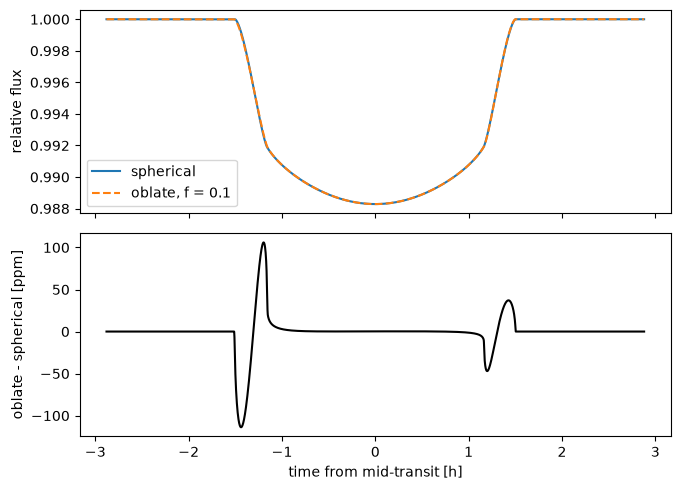

In [9]:
po = copy.copy(ph)                       # hybrid5, from A2
po.f, po.theta = 0.1, 30.0

ps = copy.copy(ph)                       # the same planet, spherical
ps.f, ps.theta = None, None

t_hr = np.linspace(-0.12, 0.12, 4001)
flux_obl = el.TransitModel(po, t_hr).light_curve(po)
flux_sph = el.TransitModel(ps, t_hr).light_curve(ps)
resid = (flux_obl - flux_sph) * 1e6
print(f"depth: oblate {(1 - flux_obl.min()) * 1e6:.0f} ppm, spherical {(1 - flux_sph.min()) * 1e6:.0f} ppm")
print(f"oblate - spherical: {resid.min():+.1f} .. {resid.max():+.1f} ppm")

if HAVE_PLT:
    fig, ax = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
    ax[0].plot(t_hr * 24, flux_sph, label="spherical"); ax[0].plot(t_hr * 24, flux_obl, "--", label="oblate, f = 0.1")
    ax[0].legend(); ax[0].set_ylabel("relative flux")
    ax[1].plot(t_hr * 24, resid, "k"); ax[1].set_ylabel("oblate - spherical [ppm]")
    ax[1].set_xlabel("time from mid-transit [h]"); plt.tight_layout(); plt.show()

## B3. What `f` and `theta` do

The residual against the equal-area sphere depends on both. With the long
axis along ($\theta = 0$) or across ($\theta = 90$) the direction of motion
the signal is symmetric in time; at other angles ingress and egress differ,
which is what makes $\theta$ measurable. The size of the signal grows
roughly linearly with $f$.

f = 0.1, theta =    0 deg: peak |residual|  75.3 ppm, time-asymmetric part   0.0 ppm
f = 0.1, theta =   30 deg: peak |residual| 113.8 ppm, time-asymmetric part  76.5 ppm
f = 0.1, theta =   60 deg: peak |residual| 113.0 ppm, time-asymmetric part  81.0 ppm
f = 0.1, theta =   90 deg: peak |residual|  68.5 ppm, time-asymmetric part   0.0 ppm


theta = 30 deg, f = 0.02: peak |residual|   21.8 ppm


theta = 30 deg, f = 0.05: peak |residual|   55.3 ppm


theta = 30 deg, f = 0.10: peak |residual|  113.8 ppm


theta = 30 deg, f = 0.20: peak |residual|  241.9 ppm


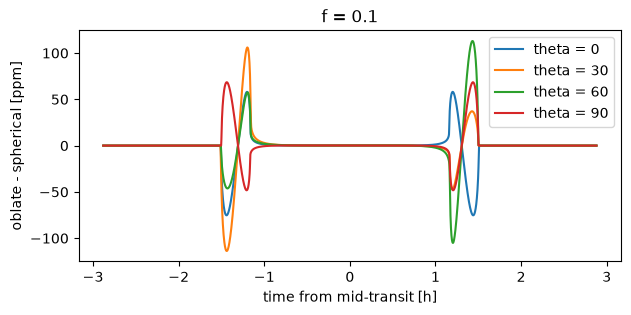

In [10]:
def residual(f, theta):
    q = copy.copy(po)
    q.f, q.theta = f, theta
    return (el.TransitModel(q, t_hr).light_curve(q) - flux_sph) * 1e6

res_theta = {theta: residual(0.1, theta) for theta in (0.0, 30.0, 60.0, 90.0)}
for theta, r_ in res_theta.items():
    asym = np.abs(r_ - r_[::-1]).max() / 2
    print(f"f = 0.1, theta = {theta:4.0f} deg: peak |residual| {np.abs(r_).max():5.1f} ppm, "
          f"time-asymmetric part {asym:5.1f} ppm")
for f in (0.02, 0.05, 0.1, 0.2):
    print(f"theta = 30 deg, f = {f:4.2f}: peak |residual| {np.abs(residual(f, 30.0)).max():6.1f} ppm")

if HAVE_PLT:
    plt.figure(figsize=(7, 3))
    for theta, r_ in res_theta.items():
        plt.plot(t_hr * 24, r_, label=f"theta = {theta:.0f}")
    plt.xlabel("time from mid-transit [h]"); plt.ylabel("oblate - spherical [ppm]")
    plt.legend(); plt.title("f = 0.1"); plt.show()

## B4. `f -> 0` is the spherical planet

At `f = 0` the oblate model equals the spherical one to rounding, and for
small `f` it departs smoothly and linearly (in float64, checked below).
One caveat for float32: below `f = 1e-5` the GPU kernels use the spherical
forms -- the flattening changes the flux by under 4e-8 there -- so the
gradient in `f` is exactly 0 in that band. A float32 sampler should start
`f` at a small positive value (1e-4 is plenty), not at 0.

In [11]:
for f in (0.0, 1e-6, 1e-4, 1e-2):
    r_ = residual(f, 30.0)
    print(f"f = {f:7.0e}: max |oblate - spherical| = {np.abs(r_).max() * 1e-6:.2e}")

f =   0e+00: max |oblate - spherical| = 1.11e-16


f =   1e-06: max |oblate - spherical| = 1.08e-09


f =   1e-04: max |oblate - spherical| = 1.08e-07


f =   1e-02: max |oblate - spherical| = 1.08e-05


## B5. Contacts, per side, and exposures

A tilted ellipse does not touch the limb at the same distance on the way in
as on the way out, so its four contact times are **not symmetric** about
mid-transit, and they differ from a sphere's. Elómë solves them per
side; the contact rule then splits each exposure at the oblate planet's own
kinks. `el.contact_offsets_oblate` exposes them (as orbital phase).

In [12]:
to_min = 3.456 / (2 * math.pi) * 24 * 60          # orbital phase -> minutes
b_ = 8.8 * math.cos(math.radians(87.0))

# the oblate planet's contacts, per side (per-chain arrays in, phases out)
with mx.stream(mx.cpu):
    arr = lambda v: mx.array([v], dtype=mx.float64)
    c_obl = el.contact_offsets_oblate(arr(8.8), arr(b_), arr(0.1), arr(0.1), arr(math.radians(30.0)))
    c_obl = [float(np.asarray(c)[0]) * to_min for c in c_obl]
# a sphere's, in closed form: sin^2(phi) = ((1 +- r)^2 - b^2) / (a^2 - b^2)
phi = [math.asin(math.sqrt(((1 + s_ * 0.1)**2 - b_**2) / (8.8**2 - b_**2))) for s_ in (1, -1)]
c_sph = [-phi[0] * to_min, -phi[1] * to_min, phi[1] * to_min, phi[0] * to_min]
for name, c in (("oblate f=0.1, 30 deg", c_obl), ("sphere, same area", c_sph)):
    print(f"{name:22s} contacts [min from mid-transit]: " + "  ".join(f"{v:+8.3f}" for v in c))

ref = el.TransitModel(po, tc, supersample_factor=401, exp_time=EXP).light_curve(po)
for label, kw in [("supersample x 7", dict(supersample_factor=7, exp_time=EXP)),
                  ("contact rule, n_gl = 5", dict(integration="contact", exp_time=EXP, n_gl=5))]:
    f_ = el.TransitModel(po, tc, **kw).light_curve(po)
    print(f"{label:24s} max |error| vs 401-point supersampling: {np.abs(f_ - ref).max():.1e}")

oblate f=0.1, 30 deg   contacts [min from mid-transit]:  -90.760   -69.212   +70.038   +90.078
sphere, same area      contacts [min from mid-transit]:  -90.230   -69.782   +69.782   +90.230


supersample x 7          max |error| vs 401-point supersampling: 2.7e-04


contact rule, n_gl = 5   max |error| vs 401-point supersampling: 4.5e-06


## B6. Eccentric orbits

Nothing changes: set `ecc` and `w` as for a spherical planet. On
`TransitParams` the orbit is fixed by `inc`, so with `inc` held the impact
parameter at conjunction, $b = a \cos i\,(1-e^2)/(1+e\sin\omega)$, moves
with the eccentricity. Below, `inc` is chosen to keep `b` -- the chord --
the same, so what changes is only the speed across the star: the same
depth, a shorter transit.

In [13]:
e_, w_ = 0.3, 40.0
cosi = b_ * (1 + e_ * math.sin(math.radians(w_))) / (8.8 * (1 - e_**2))   # same b as circular
pe = copy.copy(po)
pe.ecc, pe.w, pe.inc = e_, w_, math.degrees(math.acos(cosi))
flux_ecc = el.TransitModel(pe, t_hr).light_curve(pe)
dt_hr = (t_hr[1] - t_hr[0]) * 24
print(f"b at conjunction: {b_:.3f} (both orbits)")
print(f"depth: e = 0.3 {(1 - flux_ecc.min()) * 1e6:.0f} ppm, circular {(1 - flux_obl.min()) * 1e6:.0f} ppm")
print(f"duration: e = 0.3 {(flux_ecc < 1).sum() * dt_hr:.2f} h, circular {(flux_obl < 1).sum() * dt_hr:.2f} h")

b at conjunction: 0.461 (both orbits)
depth: e = 0.3 11714 ppm, circular 11714 ppm
duration: e = 0.3 2.41 h, circular 3.01 h


## B7. Gradients in `f` and `theta`

`light_curve_mx` differentiates in the shape too. Below, the gradient in `f`
and `theta` against central finite differences. (`theta` is in degrees, so
its gradient is per degree.)

In [14]:
with mx.stream(mx.cpu):
    mo = el.TransitModel(po, t_hr)
    def loss(f, theta):
        q = copy.copy(po)
        q.f, q.theta = f, theta
        return mx.sum(mo.light_curve_mx(q))
    x = [0.1, 30.0]
    g = mx.grad(loss, argnums=(0, 1))(*(mx.array(v, dtype=mx.float64) for v in x))
    for i, name in enumerate(("f", "theta")):
        h = 1e-5 * max(1.0, x[i])
        up, dn = list(x), list(x)
        up[i] += h; dn[i] -= h
        fd = (float(loss(*(mx.array(v, dtype=mx.float64) for v in up)))
              - float(loss(*(mx.array(v, dtype=mx.float64) for v in dn)))) / (2 * h)
        print(f"d(sum flux)/d {name:5s}: autodiff {float(g[i]):+.6e}  finite difference {fd:+.6e}")

d(sum flux)/d f    : autodiff -2.095922e-02  finite difference -2.095931e-02
d(sum flux)/d theta: autodiff +1.506240e-04  finite difference +1.506229e-04


## B8. Many parameter sets, the GPU -- and the cost

`light_curves` takes per-set `f` and `theta` like any other field, and a
float32 model runs fused Metal kernels for oblate planets too. Each point
now needs the roots of a quartic per limb-darkening pole (a hand-written
4x4 eigensolver runs in the kernel), so an oblate planet costs more than a
spherical one. Through `light_curves` the copy to numpy hides most of the
difference; on the GPU, as a sampler runs it, it shows.

In [15]:
pa_o = copy.copy(pa)                      # the 512 sets of A5 ...
pa_o.limb_dark, pa_o.u = "hybrid5", list(w5)
pa_o.f = np.clip(0.1 + 0.03 * rng.standard_normal(n_sets), 0.0, 0.4)
pa_o.theta = 30.0 + 20.0 * rng.standard_normal(n_sets)

pa_s = copy.copy(pa_o)                    # ... and the same sets, spherical
pa_s.f = pa_s.theta = None

mo32 = el.TransitModel(po, t_big, dtype=mx.float32)
ms32 = el.TransitModel(ps, t_big, dtype=mx.float32)
print("fp32 vs fp64, one oblate set:",
      f"{np.abs(mo32.light_curve(po) - el.TransitModel(po, t_big).light_curve(po)).max():.1e}")
t_o = timeit(lambda: mo32.light_curves(pa_o))
t_s = timeit(lambda: ms32.light_curves(pa_s))
print(f"light_curves, {n_sets} sets x {t_big.size:,} points (returned as numpy): "
      f"spherical {t_s:.1f} ms, oblate {t_o:.1f} ms")

# on the GPU (hybrid5 both; the oblate sets' own f and theta, in radians)
w_b = mx.array(np.tile(w5, (n_sets, 1)), dtype=mx.float32)
f_b = mx.array(pa_o.f, dtype=mx.float32)
th_b = mx.array(np.radians(pa_o.theta), dtype=mx.float32)
k_s = timeit(lambda: mx.eval(el.flux_dev_from_tau(tau_b, 3.456, 8.8, b_b, rp_b,
                                                  limb_dark="hybrid5", u=w_b)))
k_o = timeit(lambda: mx.eval(el.flux_dev_from_tau(tau_b, 3.456, 8.8, b_b, rp_b,
                                                  limb_dark="hybrid5", u=w_b, f=f_b, theta=th_b)))
print(f"flux_dev_from_tau on the GPU: spherical {k_s:.2f} ms ({k_s * 1e6 / npts:.2f} ns/pt), "
      f"oblate {k_o:.1f} ms ({k_o * 1e6 / npts:.1f} ns/pt): {k_o / k_s:.0f}x")

fp32 vs fp64, one oblate set: 1.3e-07


light_curves, 512 sets x 20,000 points (returned as numpy): spherical 51.1 ms, oblate 102.4 ms


flux_dev_from_tau on the GPU: spherical 1.93 ms (0.19 ns/pt), oblate 93.4 ms (9.1 ns/pt): 48x


The ratio depends on the law, the shapes and how much of the grid is in
transit: 15-32x for 512 chains of 5,000 points around a transit, about
50x for the sets above. With the contact rule each point costs 25
evaluations, and the spherical kernel is so cheap per evaluation that the
oblate one is ~60x it there. In absolute terms an oblate planet
on the GPU is still far faster than the CPU codes for oblate planets -- see
[Accuracy and cost](../oblate/accuracy-and-cost.md) (squishyplanet, JoJo,
GreenLantern, eclipsoid).

## B9. The sampler-facing entry point, oblate

`flux_dev_from_tau` takes `f` and `theta` (radians here) as scalars or per
chain, with every exposure rule, eccentric orbits and `ld_basis=True` --
so collapsing the limb-darkening weights works for oblate planets as well.

In [16]:
dev_o = el.flux_dev_from_tau(tau, 3.456, 8.8, b, 0.1, limb_dark="hybrid5", u=list(w5),
                             f=0.1, theta=math.radians(30.0))
B_o = el.flux_dev_from_tau(tau, 3.456, 8.8, b, 0.1, limb_dark="hybrid5", ld_basis=True,
                           f=0.1, theta=math.radians(30.0))
print("identity (B @ c)/(N @ c) == F - 1:",
      f"{np.abs(np.asarray(B_o) @ c_ / (el.hybrid_norms('hybrid5') @ c_) - np.asarray(dev_o)).max():.1e}")

# per-chain shapes, float32 on the GPU (the kernel path a sampler uses)
n = 64
tau32 = mx.array(np.tile(tau, (n, 1)), dtype=mx.float32)
f_c = mx.array(rng.uniform(0.0, 0.3, n), dtype=mx.float32)
th_c = mx.array(rng.uniform(0.0, math.pi, n), dtype=mx.float32)
loss = lambda f, th: mx.sum(el.flux_dev_from_tau(tau32, 3.456, 8.8, b, 0.1, limb_dark="hybrid5",
                                                 u=list(w5), f=f, theta=th))
gf, gth = mx.grad(loss, argnums=(0, 1))(f_c, th_c)
print("per-chain gradients:", gf.shape, gth.shape, "| finite:",
      bool(np.isfinite(np.asarray(gf)).all() and np.isfinite(np.asarray(gth)).all()))

identity (B @ c)/(N @ c) == F - 1: 5.2e-18


per-chain gradients: (64,) (64,) | finite: True


## B10. Limits and gotchas

* **Hybrid laws only.** The quadratic law's $\mu$ term has no elementary form
  along an ellipse, so `limb_dark="quadratic"` with `f` set raises. hybrid4
  and hybrid5 are the ones to use when hunting oblateness: a crude law
  (quadratic-class) can *fake* a confident oblateness signal on a
  spherical planet.
* **The domain** is $r_p \le (1-f)^{3/2}$ (0.35 at f = 0.5): there the planet
  crosses the limb at most twice. Outside it a Python number or a numpy
  array **raises**, and an `mx.array` gives **NaN**. Neither is -inf: keep
  chains inside with the prior, or map a non-finite log-likelihood to -inf
  in your sampler's wrapper.
* **`theta` has period 180 deg.** Sample it on [0, 180) and wrap. On a
  **central** transit there is a second symmetry: reflecting across the
  chord maps `theta` to `180 - theta`, and at b = 0 the two light curves are
  identical, so even the wrapped posterior has two exact modes (and nearly
  so for small b). Fold `theta` onto [0, 90] there, or expect bimodality.
* **f and theta are degenerate on central transits.** With b near 0 an
  aligned oblate planet and a smaller-b round one can look alike; that is a
  sampling problem (priors, parameterisation), not a model one.
* **fp32 below f = 1e-5** uses the spherical forms (the flattening changes
  the flux by under 4e-8 there), so d/df is 0 in that band.
* The model is fixed as spherical or oblate when you build it; switching
  `f` between `None` and a value afterwards raises -- build a new model.

In [17]:
for bad in (dict(limb_dark="quadratic", u=[0.4, 0.25]), dict(rp=0.6, f=0.5)):
    q = copy.copy(po)
    for k, v in bad.items():
        setattr(q, k, v)
    try:
        el.TransitModel(q, t).light_curve(q)
    except ValueError as err:
        print(f"{bad}: ValueError: {err}")

{'limb_dark': 'quadratic', 'u': [0.4, 0.25]}: ValueError: an oblate planet (params.f) takes a hybrid law: limb_dark='hybrid2' | 'hybrid4' | 'hybrid5'
{'rp': 0.6, 'f': 0.5}: ValueError: r_eff > (1 - f)^(3/2): the planet could cross the stellar limb more than twice, outside the oblate path's domain


# Part C -- a ringed planet

## C1. A first ringed light curve

A ring is a flat annulus around the planet's equator, seen as an
elliptical annulus on the sky. Its radii `ring_in` and `ring_out` are in
**planet radii**; `ring_f` is its projected flattening, $1 - |\cos i|$
for a ring tilted by $i$ from face-on (0 face-on, near 1 edge-on);
`theta` turns it on the sky, as it turns an oblate planet; and
`ring_tau` is its normal optical depth (`None` for opaque). Below, the
spherical hybrid5 planet of B2 with a Saturn-like ring.

depth: ringed 23813 ppm, bare planet 11714 ppm
duration: ringed 3.39 h, bare planet 3.01 h


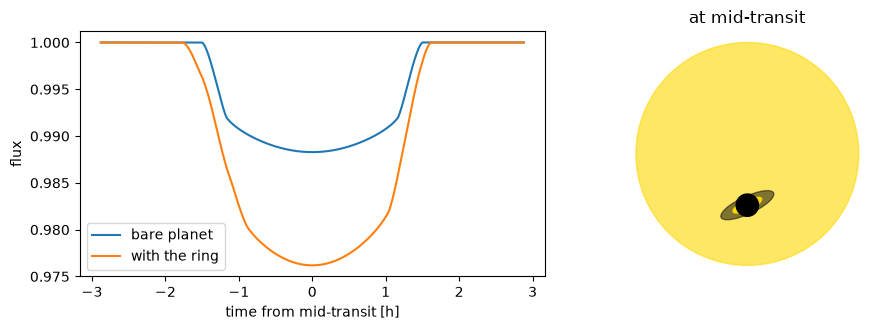

In [18]:
pr = copy.copy(ps)                       # the spherical hybrid5 planet of B2 ...
pr.ring_in, pr.ring_out = 1.4, 2.6       # ... with a ring, in planet radii
pr.ring_f, pr.theta = 0.7, 25.0          # |cos i| = 0.3; long axis 25 deg from the motion
pr.ring_tau = None                       # opaque

mr = el.TransitModel(pr, t_hr)
flux_ring = mr.light_curve(pr)
hours = lambda f_: (f_ < 1).sum() * (t_hr[1] - t_hr[0]) * 24
print(f"depth: ringed {(1 - flux_ring.min()) * 1e6:.0f} ppm, bare planet {(1 - flux_sph.min()) * 1e6:.0f} ppm")
print(f"duration: ringed {hours(flux_ring):.2f} h, bare planet {hours(flux_sph):.2f} h")

if HAVE_PLT:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    ax[0].plot(t_hr * 24, flux_sph, label="bare planet")
    ax[0].plot(t_hr * 24, flux_ring, label="with the ring")
    ax[0].set_xlabel("time from mid-transit [h]"); ax[0].set_ylabel("flux"); ax[0].legend()
    from matplotlib.patches import Circle, Ellipse
    A_o, A_i = 2.6 * 0.1, 1.4 * 0.1
    ax[1].add_patch(Circle((0, 0), 1, color="gold", alpha=0.6))
    ax[1].add_patch(Ellipse((0, -0.46), 2 * A_o, 2 * A_o * 0.3, angle=25.0, color="k", alpha=0.5))
    ax[1].add_patch(Ellipse((0, -0.46), 2 * A_i, 2 * A_i * 0.3, angle=25.0, color="gold"))
    ax[1].add_patch(Circle((0, -0.46), 0.1, color="k"))
    ax[1].set_xlim(-1.1, 1.1); ax[1].set_ylim(-1.1, 1.1); ax[1].set_aspect("equal"); ax[1].axis("off")
    ax[1].set_title("at mid-transit")
    plt.tight_layout(); plt.show()

## C2. Optical depth and tilt

A translucent ring blocks the fraction $T = 1 - e^{-\tau/|\cos i|}$ of
the light behind it, so the light curve is exactly linear in $T$, between
the bare planet ($T = 0$) and the opaque ring ($T = 1$). Tilting the ring
towards edge-on shrinks its area but raises $T$. The ring's values change
between calls on one model; only whether a ring is present is fixed.

In [19]:
def with_ring(**kw):
    q = copy.copy(pr)
    for k, v in kw.items():
        setattr(q, k, v)
    return mr.light_curve(q)

print(f"ring_tau = 0 (transparent) vs the bare planet: {np.abs(with_ring(ring_tau=0.0) - flux_sph).max():.1e}")
T = -math.expm1(-0.6 / (1 - pr.ring_f))
lin = flux_sph + T * (flux_ring - flux_sph)
print(f"ring_tau = 0.6 (T = {T:.3f}) vs the linear mix of bare and opaque: "
      f"{np.abs(with_ring(ring_tau=0.6) - lin).max():.1e}")
for rf in (0.0, 0.5, 0.7, 0.9, 0.99):
    f_ = with_ring(ring_f=rf, ring_tau=0.1)
    T_ = -math.expm1(-0.1 / (1 - rf))
    print(f"ring_tau = 0.1, ring_f = {rf:4.2f}: T = {T_:.3f}, "
          f"depth beyond the bare planet {(flux_sph.min() - f_.min()) * 1e6:5.0f} ppm")

ring_tau = 0 (transparent) vs the bare planet: 2.2e-16


ring_tau = 0.6 (T = 0.865) vs the linear mix of bare and opaque: 1.1e-16


ring_tau = 0.1, ring_f = 0.00: T = 0.095, depth beyond the bare planet  5257 ppm


ring_tau = 0.1, ring_f = 0.50: T = 0.181, depth beyond the bare planet  4568 ppm


ring_tau = 0.1, ring_f = 0.70: T = 0.283, depth beyond the bare planet  3430 ppm


ring_tau = 0.1, ring_f = 0.90: T = 0.632, depth beyond the bare planet  2353 ppm


ring_tau = 0.1, ring_f = 0.99: T = 1.000, depth beyond the bare planet   369 ppm


## C3. Gradients in the ring

`light_curve_mx` differentiates in every ring field and in `theta`, as in
every other parameter. A translucent ring here, so `ring_tau` has a
gradient too (an opaque ring is `ring_tau = None`, a constant).

In [20]:
t_g = np.linspace(-0.12, 0.12, 401)
names = ("ring_in", "ring_out", "ring_f", "ring_tau", "theta")
x0 = [1.4, 2.6, 0.7, 0.6, 25.0]
pg = copy.copy(pr)
pg.ring_tau = 0.6
mg = el.TransitModel(pg, t_g)

with mx.stream(mx.cpu):
    def loss(*vals):
        q = copy.copy(pg)
        for k, v in zip(names, vals):
            setattr(q, k, v)
        return mx.sum(mg.light_curve_mx(q))
    arr64 = lambda v: mx.array(v, dtype=mx.float64)
    g = mx.grad(loss, argnums=tuple(range(len(names))))(*map(arr64, x0))
    for i, name in enumerate(names):
        h = 1e-6 * max(1.0, x0[i])
        up, dn = list(x0), list(x0)
        up[i] += h; dn[i] -= h
        fd = (float(loss(*map(arr64, up))) - float(loss(*map(arr64, dn)))) / (2 * h)
        print(f"d(sum flux)/d {name:8s}: autodiff {float(g[i]):+.6e}  finite difference {fd:+.6e}")

d(sum flux)/d ring_in : autodiff +7.176188e-01  finite difference +7.176188e-01


d(sum flux)/d ring_out: autodiff -2.116762e+00  finite difference -2.116762e+00


d(sum flux)/d ring_f  : autodiff +5.048900e+00  finite difference +5.048900e+00


d(sum flux)/d ring_tau: autodiff -8.857604e-01  finite difference -8.857604e-01


d(sum flux)/d theta   : autodiff +6.379722e-04  finite difference +6.379730e-04


## C4. The GPU, and the cost

A float32 model runs fused Metal kernels for ringed planets too. Every
outline -- the planet and both ring edges -- is integrated, each split
into arcs where it crosses the others, so a ring costs about 10-20 times
an oblate planet.

In [21]:
mr32 = el.TransitModel(pr, t_big, dtype=mx.float32)
print("fp32 vs fp64, one ringed set:",
      f"{np.abs(mr32.light_curve(pr) - el.TransitModel(pr, t_big).light_curve(pr)).max():.1e}")
k_r = timeit(lambda: mx.eval(el.flux_dev_from_tau(tau_b, 3.456, 8.8, b_b, rp_b,
                                                  limb_dark="hybrid5", u=w_b, theta=th_b,
                                                  ring_in=1.4, ring_out=2.6, ring_f=0.7)))
print(f"flux_dev_from_tau on the GPU, {n_sets} sets x {t_big.size:,} points: "
      f"spherical {k_s:.2f} ms, oblate {k_o:.1f} ms, ringed {k_r:.1f} ms "
      f"({k_r / k_o:.0f}x oblate)")

fp32 vs fp64, one ringed set: 1.5e-07


flux_dev_from_tau on the GPU, 512 sets x 20,000 points: spherical 1.93 ms, oblate 93.4 ms, ringed 820.9 ms (9x oblate)


In float64 on the CPU, a ringed light curve takes about 40 microseconds
per point -- seconds for $10^5$ points -- which is fine for a single
curve but not for a sampler; use float32 on the GPU for fitting. See
[Ringed planets](../rings/index.md) for the geometry, exposures and
fitting, and [Accuracy, cost and fitting](../rings/accuracy-and-fitting.md)
for the comparison with other ringed-planet codes.

# Summary

| | spherical | oblate | ringed |
|---|---|---|---|
| turn on | default (`f = None`) | `p.f`, `p.theta` [deg]; `flux_dev_from_tau(f=, theta=)` [rad] | `p.ring_in`, `ring_out`, `ring_f`, `ring_tau`, `theta`; the same keywords in `flux_dev_from_tau` |
| limb darkening | any | hybrid2 / hybrid4 / hybrid5 | hybrid2 / hybrid4 / hybrid5 |
| float64 accuracy | ~1e-16 | ~1e-16 (vs a 30-digit integral) | ~1e-16 (vs brute-force integrals) |
| float32 (GPU) accuracy | ~1e-7 | ~1e-7 | ~1e-7 |
| exposures, eccentric orbits, gradients, batching, `ld_basis` | yes | yes | yes |
| cost (fp32 GPU) | ~0.2 ns per point | tens of times that (15-32x; B8 measures this notebook's case); ~60x under the contact rule | 10-20x an oblate planet (C4) |

## Where to go next

* [Oblate planets](../oblate/index.md) -- the geometry, light curves,
  accuracy and cost, and fitting.
* [Ringed planets](../rings/index.md) -- the same for a planet with a ring.
* [The hybrid limb-darkening laws](../reference/hybrid-laws.md) -- their
  definitions and priors.
* [Many parameter sets at once](../guides/batching.md) -- batching for
  samplers.
* [Accuracy and cost](../oblate/accuracy-and-cost.md) -- against
  squishyplanet, JoJo, GreenLantern and eclipsoid.
* [Tutorial 1](01_elome_with_anvil.ipynb) -- fitting a transit with anvil's HMC.